<a href="https://colab.research.google.com/github/nat-petty/MMA3001-project/blob/main/MMA3001projectNP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MMA3001 — Combined Cycle Power Plant Output Prediction**

Aim: Predict net electrical output (PE, MW) using Average Temperature (AT) (°C), Exhaust Vacuum (V) (cm Hg), Ambient Pressure (AP) (mbar), Relative Humidity (RH) (%). Compare a linear baseline with nonlinear models and validate using the five provided shuffled sheets.

Note: Five sheets are reorderings of the same 9,568 records, not 47,840 independent samples. Never concatenate them to increase the dataset size. Use Sheet1 for exploratory analysis and model selection; use all five sheets for the supplied 5×2 validation protocol. This is not chronological forecasting: no timestamps are provided. Results apply to full-load operation within the sampled conditions.



**Install Packages and Load the Data**

In [4]:
%pip -q install pandas odfpy scikit-learn matplotlib seaborn joblib pytest pdoc

from pathlib import Path
import os, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from joblib import dump
SEED = 42
sns.set_theme(style='whitegrid')
DATA = Path('data/Folds5x2_pp.ods')
if not DATA.exists():
    DATA = Path('Folds5x2_pp.ods')
if not DATA.exists():
    try:
        from google.colab import files
        print('Upload Folds5x2_pp.ods')
        uploaded = files.upload()
        DATA = Path('Folds5x2_pp.ods')
    except ImportError:
        raise FileNotFoundError('Place Folds5x2_pp.ods in data/ or current directory')
assert DATA.exists(), 'Dataset not found'
OUTPUT = Path('results'); OUTPUT.mkdir(exist_ok=True)
sheets = pd.read_excel(DATA, sheet_name=None, engine='odf')
print('Sheets:', {name: df.shape for name, df in sheets.items()})
df = sheets['Sheet1'].copy()
display(df.head())

Sheets: {'Sheet1': (9568, 5), 'Sheet2': (9568, 5), 'Sheet3': (9568, 5), 'Sheet4': (9568, 5), 'Sheet5': (9568, 5)}


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


**Verify dataset integrity and data dictionary**

Check dimensions, data types, missing/non-finite values, duplicates, and whether all five sheets contain the same observations. Duplicates are reported rather than automatically deleted and no imputing is done without evidence.

In [5]:
FEATURES = ['AT','V','AP','RH']; TARGET = 'PE'
expected = FEATURES + [TARGET]
for name, frame in sheets.items():
    assert list(frame.columns) == expected, (name, frame.columns.tolist())
    assert frame.shape == (9568,5), (name,frame.shape)
    assert all(pd.api.types.is_numeric_dtype(frame[c]) for c in expected)
    assert np.isfinite(frame[expected].to_numpy()).all(), f'Nonfinite values in {name}'
reference = df.value_counts(dropna=False).sort_index()
for name, frame in sheets.items():
    assert reference.equals(frame.value_counts(dropna=False).sort_index()), f'{name} is not the same multiset'
print('Missing values:\n', df.isna().sum())
print('Exact duplicate rows:',df.duplicated().sum())
display(df.describe().T)
display(df.corr(numeric_only=True).round(3))

Missing values:
 AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64
Exact duplicate rows: 41


,count,mean,std,min,25%,50%,75%,max
AT,9568.0,19.651231,7.452473,1.81,13.5100,20.345,25.72,37.11
V,9568.0,54.305804,12.707893,25.36,41.7400,52.080,66.54,81.56
AP,9568.0,1013.259078,5.938784,992.89,1009.1000,1012.940,1017.26,1033.30
RH,9568.0,73.308978,14.600269,25.56,63.3275,74.975,84.83,100.16
PE,9568.0,454.365009,17.066995,420.26,439.7500,451.550,468.43,495.76


,AT,V,AP,RH,PE
AT,1.000,0.844,-0.508,-0.543,-0.948
V,0.844,1.000,-0.414,-0.312,-0.870
AP,-0.508,-0.414,1.000,0.100,0.518
RH,-0.543,-0.312,0.100,1.000,0.390
PE,-0.948,-0.870,0.518,0.390,1.000


**Exploratory data analysis**

Interpret distributions, unusual observations, pairwise relationships, and whether linearity is plausible. Correlation does not prove causation.

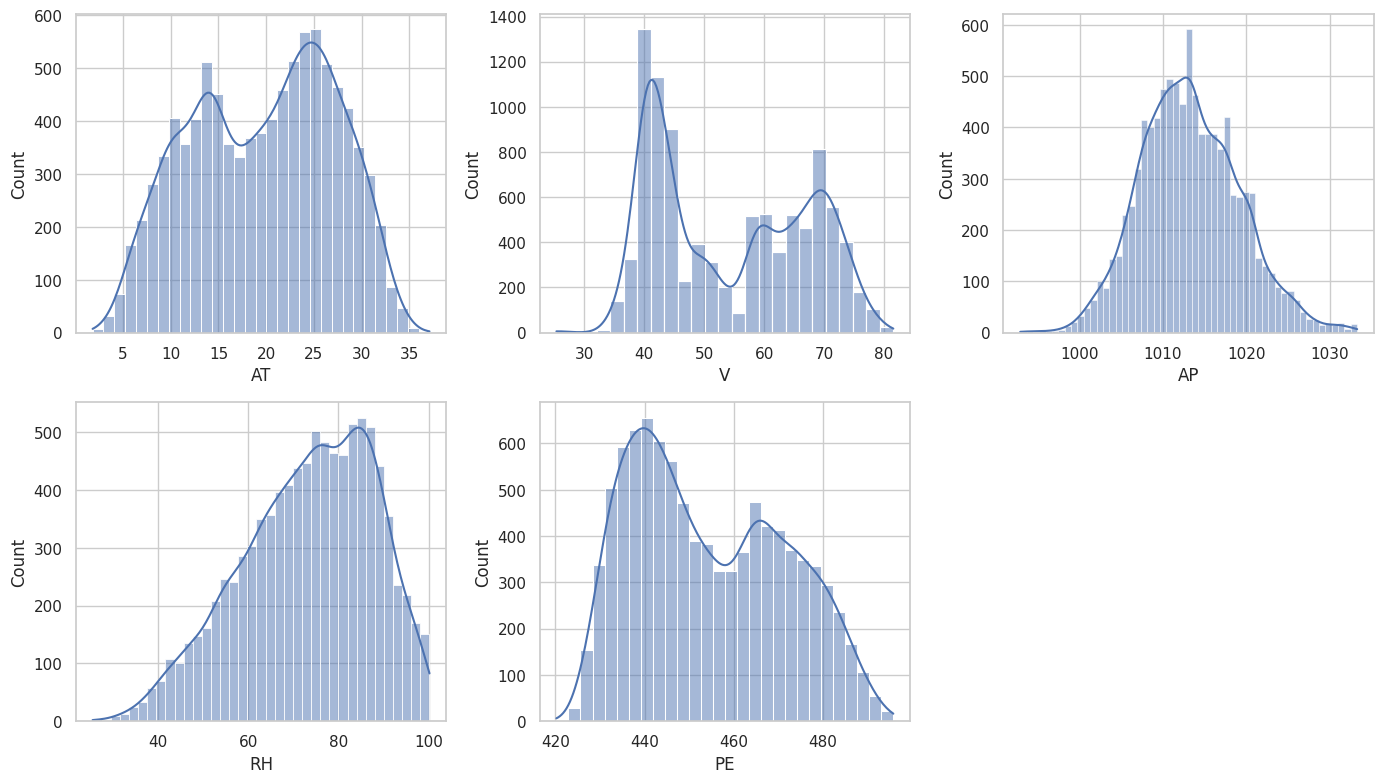

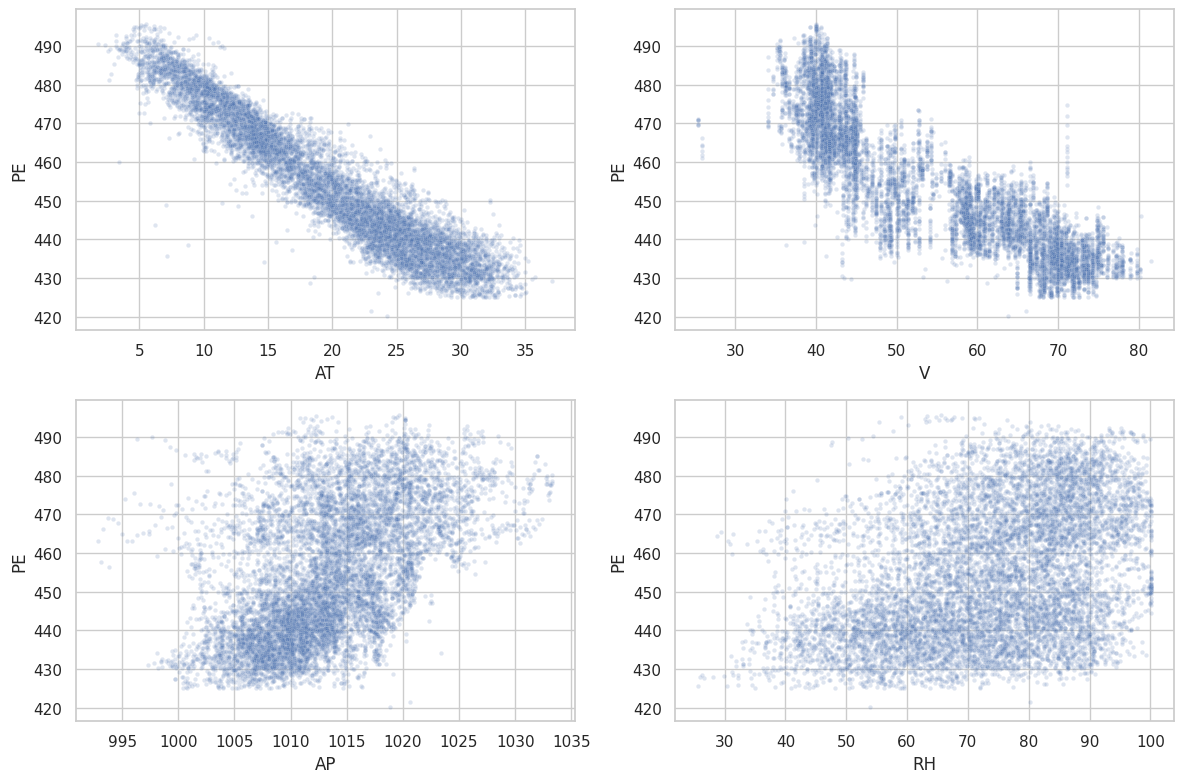

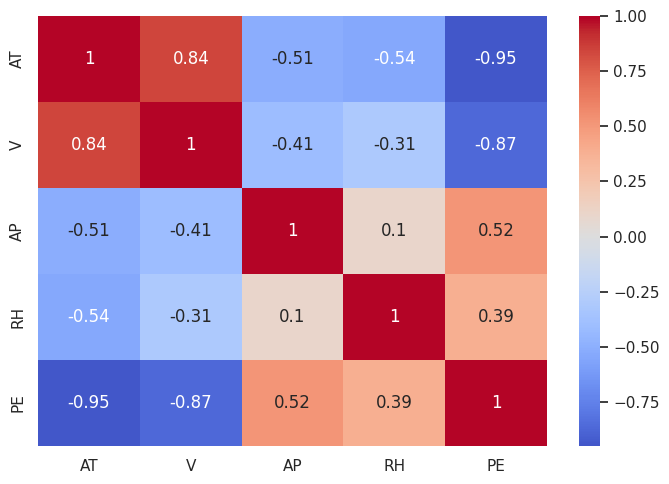

In [6]:
fig, axes = plt.subplots(2,3,figsize=(14,8))
for ax,col in zip(axes.flat,expected):
    sns.histplot(df[col],kde=True,ax=ax)
for ax in axes.flat[len(expected):]:ax.axis('off')
plt.tight_layout();plt.savefig(OUTPUT/'distributions.png',dpi=160);plt.show()
fig, axes = plt.subplots(2,2,figsize=(12,8))
for ax,col in zip(axes.flat,FEATURES):
    sns.scatterplot(data=df,x=col,y=TARGET,alpha=.18,s=10,ax=ax)
plt.tight_layout();plt.savefig(OUTPUT/'feature_scatter.png',dpi=160);plt.show()
plt.figure(figsize=(7,5));sns.heatmap(df.corr(),annot=True,cmap='coolwarm',center=0);plt.tight_layout();plt.savefig(OUTPUT/'correlations.png',dpi=160);plt.show()

**Holdout design and baseline models**

Create a 20% test set once on sheet1. All tuning and selection use the remaining 80%. The untouched test set is evaluated only after selecting a model. A mean predictor is a sanity-check baseline, and ordinary least squares is the primary engineering baseline.

In [7]:
X=df[FEATURES];y=df[TARGET]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=SEED)
def metrics(y_true,y_pred):
    return {'MAE_MW':mean_absolute_error(y_true,y_pred),
            'RMSE_MW':np.sqrt(mean_squared_error(y_true,y_pred)),
            'R2':r2_score(y_true,y_pred)}
models={'Mean baseline':DummyRegressor(strategy='mean'),
        'Linear regression':LinearRegression(),
        'Random forest':RandomForestRegressor(n_estimators=150,min_samples_leaf=2,n_jobs=-1,random_state=SEED),
        'Histogram gradient boosting':HistGradientBoostingRegressor(max_iter=200,learning_rate=.1,random_state=SEED)}
cv=KFold(n_splits=5,shuffle=True,random_state=SEED)
rows=[]
for name,model in models.items():
    start=time.perf_counter()
    scores=cross_validate(model,X_train,y_train,cv=cv,scoring={'mae':'neg_mean_absolute_error','rmse':'neg_root_mean_squared_error','r2':'r2'},n_jobs=1)
    elapsed=time.perf_counter()-start
    rows.append({'model':name,'CV_MAE_MW':-scores['test_mae'].mean(),
                 'CV_RMSE_MW':-scores['test_rmse'].mean(),'CV_R2':scores['test_r2'].mean(),
                 'CV_RMSE_SD':scores['test_rmse'].std(ddof=1),'CV_seconds':elapsed})
cv_results=pd.DataFrame(rows).sort_values('CV_RMSE_MW')
display(cv_results)
cv_results.to_csv(OUTPUT/'model_comparison_cv.csv',index=False)

,model,CV_MAE_MW,CV_RMSE_MW,CV_R2,CV_RMSE_SD,CV_seconds
3,Histogram gradient boosting,2.363813,3.282360,0.962945,0.180798,2.622226
2,Random forest,2.491006,3.470456,0.958586,0.168899,22.062169
1,Linear regression,3.631517,4.572106,0.928221,0.089715,0.161940
0,Mean baseline,14.851048,17.073684,-0.000131,0.195793,0.057572


**Tune the best nonlinear candidate**

Use only the training set for tuning. Runtime varies by hardware. Compare tuned and untuned validation scores, not just training fit.

In [10]:
candidate=RandomForestRegressor(random_state=SEED,n_jobs=-1)
search=GridSearchCV(candidate,{'n_estimators':[100,200], 'min_samples_leaf':[1,3,5], 'max_features':[0.7,1.0]},
                    scoring='neg_root_mean_squared_error',cv=cv,n_jobs=-1,refit=True)
t0=time.perf_counter();search.fit(X_train,y_train);tuning_seconds=time.perf_counter()-t0
print('Best RF settings:',search.best_params_,'CV RMSE (MW):',-search.best_score_,'Time (s):',round(tuning_seconds,2))
selected_name=cv_results.iloc[0]['model']
selected_model=models[selected_name]
# Select between tuned RF and the best default model using training CV only.
if -search.best_score_ < cv_results.iloc[0]['CV_RMSE_MW']:
    selected_name='Tuned random forest';selected_model=search.best_estimator_
else:
    selected_model.fit(X_train,y_train)
print('Selected by CV:',selected_name)

Best RF settings: {'max_features': 0.7, 'min_samples_leaf': 1, 'n_estimators': 200} CV RMSE (MW): 3.345173000910562 Time (s): 180.91
Selected by CV: Histogram gradient boosting


**Final withheld test evaluation**

Only now use the held-out test data. Evaluate the selected model and the linear regression baseline on identical observations. A test score is not an unbiased estimate if you repeatedly change models after seeing it.

,model,MAE_MW,RMSE_MW,R2,predict_seconds
0,Linear regression,3.595913,4.502633,0.930105,0.001392
1,Histogram gradient boosting,2.263922,3.114848,0.966551,0.039299


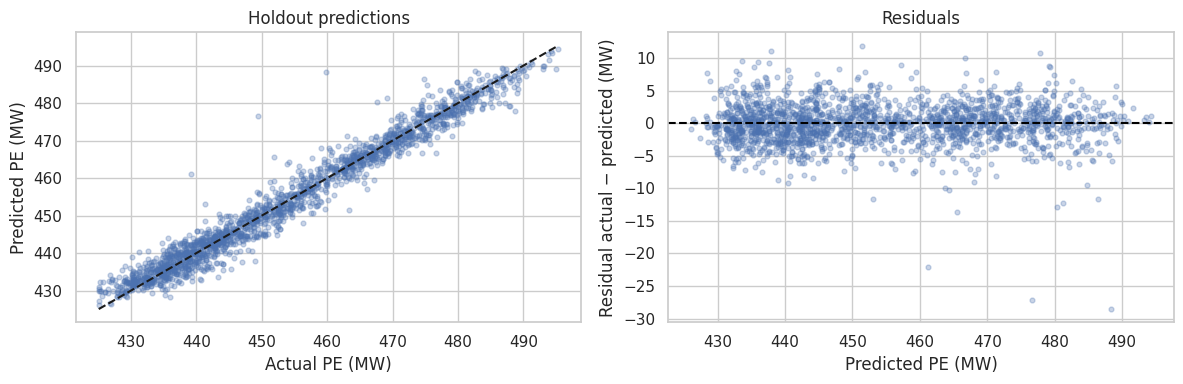

['results/selected_model.joblib']

In [11]:
linear=LinearRegression().fit(X_train,y_train)
if selected_name!='Tuned random forest':selected_model.fit(X_train,y_train)
rows=[]
for name,model in [('Linear regression',linear),(selected_name,selected_model)]:
    start=time.perf_counter(); pred=model.predict(X_test);pred_seconds=time.perf_counter()-start
    rows.append({'model':name,**metrics(y_test,pred),'predict_seconds':pred_seconds})
test_results=pd.DataFrame(rows);display(test_results)
test_results.to_csv(OUTPUT/'holdout_results.csv',index=False)
pred=selected_model.predict(X_test)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(y_test,pred,alpha=.3,s=12)
lims=[min(y_test.min(),pred.min()),max(y_test.max(),pred.max())]
axes[0].plot(lims,lims,'k--');axes[0].set(xlabel='Actual PE (MW)',ylabel='Predicted PE (MW)',title='Holdout predictions')
axes[1].scatter(pred,y_test-pred,alpha=.3,s=12);axes[1].axhline(0,color='black',linestyle='--')
axes[1].set(xlabel='Predicted PE (MW)',ylabel='Residual actual − predicted (MW)',title='Residuals')
plt.tight_layout();plt.savefig(OUTPUT/'holdout_diagnostics.png',dpi=160);plt.show()
dump(selected_model,OUTPUT/'selected_model.joblib')

**Five repetitions of two-fold validation**

The supplied sheets are five shuffled orderings of the same observations. For each sheet, train on the first half and evaluate on the second; then swap halves. This produces ten paired test measurements for linear regression and the selected approach. Important: Model selection above already used Sheet1; therefore this is a repeated robustness comparison, not a completely independent post-selection confirmation.

In [14]:
sheets = pd.read_excel(
    "Folds5x2_pp.ods",
    sheet_name=None,
    engine="odf"
)

# Check that all five worksheets loaded correctly
print("Worksheet names:", list(sheets.keys()))

for name, frame in sheets.items():
    print(f"{name}: {frame.shape}")

Worksheet names: ['Sheet1', 'Sheet2', 'Sheet3', 'Sheet4', 'Sheet5']
Sheet1: (9568, 5)
Sheet2: (9568, 5)
Sheet3: (9568, 5)
Sheet4: (9568, 5)
Sheet5: (9568, 5)


In [15]:
from sklearn.base import clone
fold_rows=[]
for repeat,(sheet_name,frame) in enumerate(sheets.items(),start=1):
    n=len(frame);half=n//2
    for fold,(train_ids,test_ids) in enumerate([(np.arange(half),np.arange(half,n)),(np.arange(half,n),np.arange(half))],start=1):
        xtr=frame.iloc[train_ids][FEATURES]; ytr=frame.iloc[train_ids][TARGET]
        xte=frame.iloc[test_ids][FEATURES]; yte=frame.iloc[test_ids][TARGET]
        for name,est in [('Linear regression',LinearRegression()),(selected_name,clone(selected_model))]:
            start=time.perf_counter();est.fit(xtr,ytr);fit_seconds=time.perf_counter()-start
            prediction=est.predict(xte)
            fold_rows.append({'repeat':repeat,'fold':fold,'model':name,**metrics(yte,prediction),'fit_seconds':fit_seconds})
fold_results=pd.DataFrame(fold_rows)
fold_results.to_csv(OUTPUT/'five_by_two_results.csv',index=False)
display(fold_results.groupby('model')[['MAE_MW','RMSE_MW','R2','fit_seconds']].agg(['mean','std']).round(3))
paired=fold_results.pivot(index=['repeat','fold'],columns='model',values='RMSE_MW')
print('Per-fold RMSE differences (selected minus linear):')
display(paired.assign(difference=paired[selected_name]-paired['Linear regression']))
print('NOTE: 10 scores are dependent because the training/test observations recur. Do not treat them as 10 independent experiments.')

MAE_MW        RMSE_MW            R2         \
                              mean    std    mean    std   mean    std   
model                                                                    
Histogram gradient boosting  2.442  0.039   3.369  0.050  0.961  0.001   
Linear regression            3.629  0.030   4.562  0.054  0.929  0.002   

                            fit_seconds         
                                   mean    std  
model                                           
Histogram gradient boosting       0.717  0.495  
Linear regression                 0.005  0.007

Per-fold RMSE differences (selected minus linear):


model        Histogram gradient boosting  Linear regression  difference
repeat fold                                                            
1      1                        3.356127           4.583923   -1.227796
       2                        3.394634           4.539616   -1.144982
2      1                        3.374513           4.580414   -1.205901
       2                        3.427312           4.548709   -1.121397
3      1                        3.360885           4.569912   -1.209027
       2                        3.356607           4.549820   -1.193213
4      1                        3.268586           4.456421   -1.187835
       2                        3.414959           4.662779   -1.247820
5      1                        3.313417           4.524147   -1.210730
       2                        3.423562           4.599711   -1.176149

NOTE: 10 scores are dependent because the training/test observations recur. Do not treat them as 10 independent experiments.


**Sensitivity and engineering interpretation**

Permutation importance measures how much test error rises when one variable is shuffled. Correlated inputs can share importance, so this is not a causal effect. Partial dependence shows the model response when a feature changes while averaging over other observed features; unrealistic feature combinations are a limitation.

,feature,RMSE_increase_MW,SD
0,AT,16.677320,0.274691
1,V,3.397773,0.062211
2,AP,0.880793,0.027227
3,RH,0.832794,0.048746


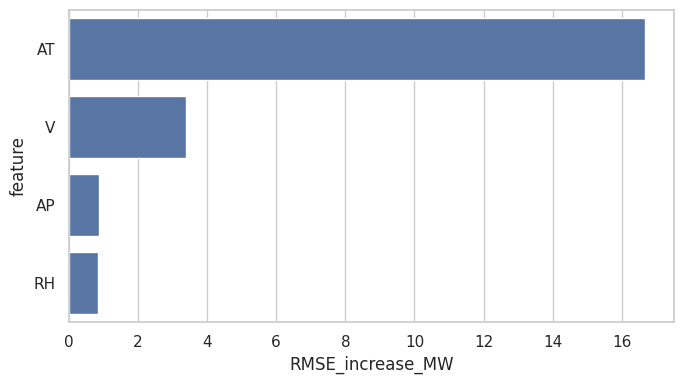

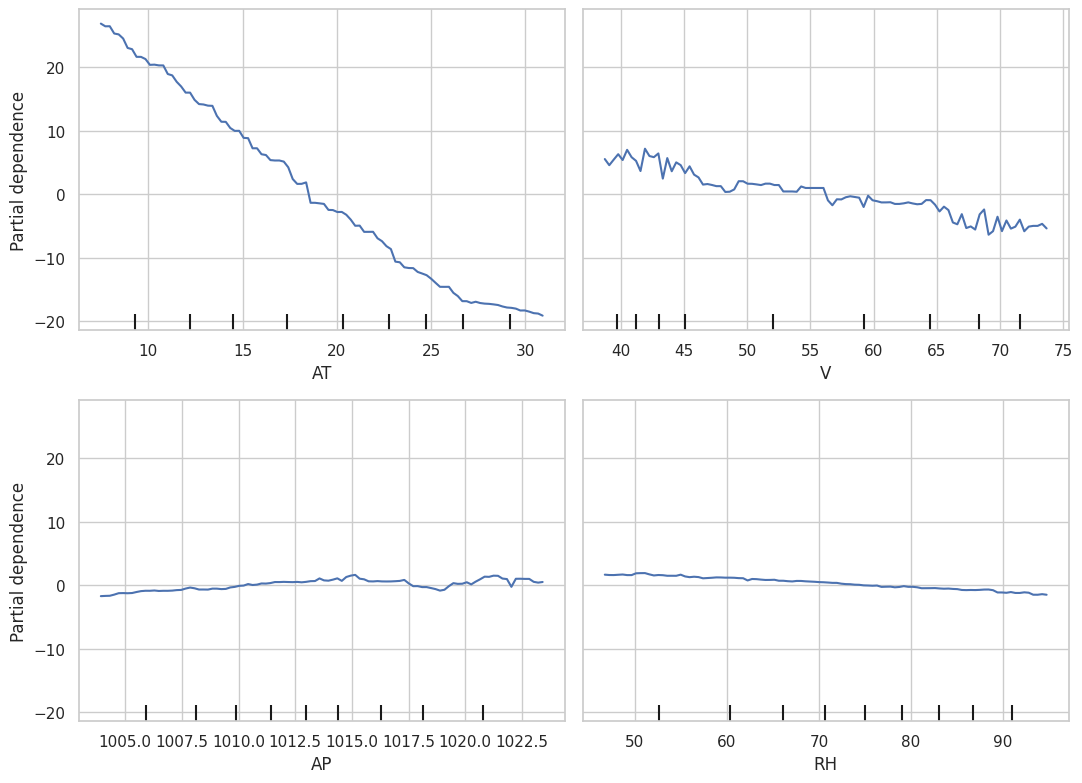

In [16]:
importance=permutation_importance(selected_model,X_test,y_test,n_repeats=10,random_state=SEED,scoring='neg_root_mean_squared_error')
imp=pd.DataFrame({'feature':FEATURES,'RMSE_increase_MW':importance.importances_mean,'SD':importance.importances_std}).sort_values('RMSE_increase_MW',ascending=False)
display(imp);imp.to_csv(OUTPUT/'permutation_importance.csv',index=False)
plt.figure(figsize=(7,4));sns.barplot(data=imp,x='RMSE_increase_MW',y='feature');plt.tight_layout();plt.savefig(OUTPUT/'importance.png',dpi=160);plt.show()
fig,axes=plt.subplots(2,2,figsize=(11,8))
PartialDependenceDisplay.from_estimator(selected_model,X_train,FEATURES,ax=axes)
plt.tight_layout();plt.savefig(OUTPUT/'partial_dependence.png',dpi=160);plt.show()

**Robustness checks and uncertainty**

Check performance by temperature quartile and bootstrap the fixed test predictions to estimate uncertainty in holdout RMSE. Bootstrap intervals describe test-sample variation conditional on this fitted model, not uncertainty from training or temporal drift.

In [17]:
diagnostics=X_test.copy();diagnostics['actual']=y_test.to_numpy();diagnostics['predicted']=pred
diagnostics['temp_group']=pd.qcut(diagnostics['AT'],4,duplicates='drop')
for group,sub in diagnostics.groupby('temp_group',observed=True):
    print(group,metrics(sub['actual'],sub['predicted']))
rng=np.random.default_rng(SEED);actual=y_test.to_numpy();predicted=np.asarray(pred)
boot=[]
for _ in range(1000):
    ids=rng.integers(0,len(actual),len(actual))
    boot.append(np.sqrt(np.mean((actual[ids]-predicted[ids])**2)))
print('Bootstrap 95% RMSE interval (MW):',np.quantile(boot,[.025,.975]))
summary={'selected_model':selected_name,'holdout':test_results.to_dict(orient='records'),
         'best_rf_params':search.best_params_,'rf_tuning_seconds':tuning_seconds,
         'rmse_bootstrap_95_percent':np.quantile(boot,[.025,.975]).tolist()}
(OUTPUT/'summary.json').write_text(json.dumps(summary,indent=2))

(2.339, 13.52] {'MAE_MW': 2.3917202666758755, 'RMSE_MW': np.float64(3.6065175263264364), 'R2': 0.7636898727024961}
(13.52, 20.315] {'MAE_MW': 2.0922513252423567, 'RMSE_MW': np.float64(2.8917159223538653), 'R2': 0.8374907707847823}
(20.315, 25.998] {'MAE_MW': 2.18096272510135, 'RMSE_MW': np.float64(2.8259857416947702), 'R2': 0.810545278871667}
(25.998, 37.11] {'MAE_MW': 2.389595004323511, 'RMSE_MW': np.float64(3.072106544893143), 'R2': 0.6674540419216346}
Bootstrap 95% RMSE interval (MW): [2.90053087 3.35333676]


710